# Yes, RL Can Run a Building: Residual PPO

People say reinforcement learning cannot beat a hand-written controller here.
This notebook shows one that does, on buildings it never trained on, and submits it.

| | held-out building 8 (30 days, 5 climates) | public leaderboard |
|---|---:|---:|
| public per-zone PI controller (zt) | 0.01358 | 0.01420 |
| the hand rule under our RL (zt + off-hours rule) | 0.01251 | |
| RL residual on that rule, seed 0, 2.0M steps | 0.01136 | 0.01237 |
| RL residual, seed 0, 2.5M steps | 0.01100 | 0.01245 |
| RL residual, seed 0, 3.0M steps (version 1 of this notebook) | 0.01065 | 0.01224 |
| RL residual, seed 1, 4.75M steps (version 2) | 0.01051 | 0.01216 |
| **RL residual, seed 1, 5.0M steps (versions 3 and 4, this notebook's weights)** | **0.01040** | **0.01199** |

Lower is better.
**Read section 4b before trusting the size of the gain:** part of it comes from a simulator billing bug the RL found on its own.
Billed honestly, the gain is -10.6%, not -16.9%; under the organisers' fix (PR #2) it is -9.0%. It is still a real gain.
Everything below is measured; the training logs behind every plot ship in the dataset `smart-buildings-residual-rl`.
The sections: 0 the problem, 1 the idea, 2 the network, 3 training, 4 results, 4b the billing bug (what is real), 4c what the RL cannot reach, 5 what failed, 6 where next, 7 the submission.

## 0. The problem

Control the HVAC of an unseen office building every 5 minutes for 30 days (8,640 steps).
Each step the policy reads the building's sensors and sends setpoints and on/off commands.
The reward mixes comfort, energy and carbon; the score is the mean over scenarios of `abs(mean(reward))`, lower is better.

Training data: 6 buildings (`building_train_1, 2, 4, 5, 7, 8`), each in 5 climates (Atlanta, Denver, Fairbanks, Phoenix, Singapore).
A building has 30-85 zones (rooms, each with a VAV box), 3-9 air handlers (AHUs) and one hot-water plant.
The test buildings are hidden, so a policy must work on a building it has never seen.

| entity | what it reads | what it commands |
|---|---|---|
| zone (VAV) | air temperature, heating/cooling setpoints, damper and reheat valve | damper, reheat valve |
| AHU | supply air temperature and pressure, flows, outside air temperature, fan commands | supply temperature, static pressure, recirculation, run on/off |
| plant | hot-water supply temperature, pressure, run status | water temperature, pressure, pump on/off |
| global | time of day and week, occupancy, comfort mode now and soon | |

Below: one real training scenario, its size and a few raw observations.

In [1]:
import os, sys, json, shutil
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

candidates = [Path('/kaggle/input/competitions/neurips-2026-smart-buildings'), Path('/kaggle/input/neurips-2026-smart-buildings')]
DATA_ROOT = next(p for p in candidates if (p / 'smart_buildings').exists())
sys.path.insert(0, str(DATA_ROOT)); sys.path.insert(0, str(DATA_ROOT / 'kaggle_evaluation'))
W = next(Path(p) for p, d, f in os.walk('/kaggle/input') if 'skynet.pt' in f)
os.makedirs('/tmp/pkg/skynet', exist_ok=True)                       # rebuild the package the dataset stores flat
for f in ('__init__.py', 'base.py', 'features.py', 'nets.py', 'policy.py', 'zt_controller.py'):
    shutil.copy(W / f, f'/tmp/pkg/skynet/{f}')
sys.path.insert(0, '/tmp/pkg')
C = json.loads((W / 'curves.json').read_text())
RERUN = os.getenv('KAGGLE_IS_COMPETITION_RERUN') is not None
print('data', DATA_ROOT, '| weights', (W / 'TAG.txt').read_text().strip(), '| scoring rerun:', RERUN)

data /kaggle/input/neurips-2026-smart-buildings | weights m1c_ztoff_s10_seed1@5001216 SkynetPolicy | scoring rerun: False


In [2]:
SCEN = DATA_ROOT / 'smart_buildings' / 'training_scenarios'
if not RERUN and SCEN.exists():
    import gin  # noqa: F401  (the simulator's config system)
    cwd = os.getcwd(); os.chdir(DATA_ROOT)
    try:
        from smart_buildings import evaluate as E
        d = SCEN / 'building_train_8' / 'atlanta_1'
        env = E.load_hybrid_environment(d / 'config.gin'); env.metrics_path = None
        meta = E.create_building_meta_data(env, d)
        obs, _ = env.reset()
        names = list(meta['observation_field_names'])
        print(f"building_train_8 / atlanta_1: {len(meta['zone_temp_indices'])} zones, {len(meta['temp_indices'])} AHUs, "
              f"{len(names)} observation fields, {meta['n_continuous_action']} continuous + {meta['n_discrete_action']} discrete actions")
        for n in [x for x in names if x.startswith('VAV')][:6] + [x for x in names if x.startswith('ahs')][:4] + ['num_occupants', 'hod_sin_000']:
            print(f'  {n:60s} {obs[names.index(n)]: .4f}')
    finally:
        os.chdir(cwd)
else:
    print('training scenarios not mounted (or scoring rerun): skipping the look at the data')

building_train_8 / atlanta_1: 30 zones, 3 AHUs, 283 observation fields, 71 continuous + 4 discrete actions
  VAV_1_reheat_valve_percentage_command                        -1.0000
  VAV_1_supply_air_damper_percentage_command                   -0.8000
  VAV_1_supply_air_flowrate_setpoint                            2.0000
  VAV_1_zone_air_cooling_temperature_setpoint_sensor            297.0000
  VAV_1_zone_air_heating_temperature_setpoint_sensor            294.0000
  VAV_1_zone_air_temperature_sensor                            -0.2000
  ahs_ahu_1_cooling_request_count                               0.0000
  ahs_ahu_1_discharge_fan_speed_percentage_command              0.0000
  ahs_ahu_1_exhaust_fan_run_command                             1.0000
  ahs_ahu_1_outside_air_flowrate_sensor                         0.0000
  num_occupants                                                 0.0000
  hod_sin_000                                                   1.0000


## 1. The idea: learn a correction, not a controller

A policy that starts from random actions spends its first million steps freezing and cooking the building.
So the RL does not replace the controller; it adds a bounded correction to a decent hand rule:

    action = clip(rule_action + correction, -1, 1)        correction = network output, last layer initialised to zero

At step 0 the correction is exactly zero, so the untrained policy **is** the rule: it scores the rule's 0.01251 on day one,
and every PPO update can only be judged against that.

The rule (`zt_off`) is the public per-zone PI controller of **malyshevdanil** ([Smart Buildings Probe ZT Best](https://www.kaggle.com/code/malyshevdanil/smart-buildings-probe-zt-best), Apache-2.0)
in its PI hours, plus an off-hours rule (everything to minimum, recirculation on, switches off).
The RL acts only in the PI hours; outside them the rule acts alone.

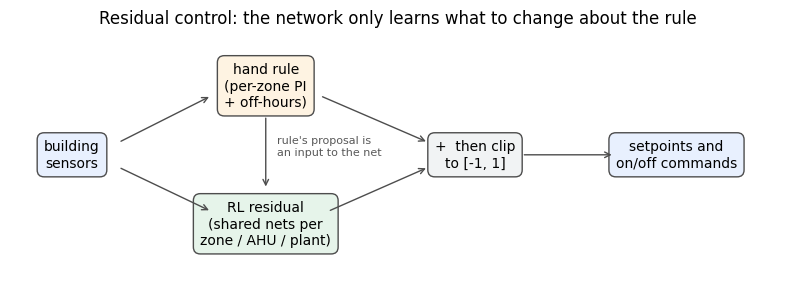

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.2)); ax.axis('off')
box = lambda x, y, t, c: ax.text(x, y, t, ha='center', va='center', fontsize=10, bbox=dict(boxstyle='round,pad=0.5', fc=c, ec='0.3'))
box(0.08, 0.5, 'building\nsensors', '#e8f0fe'); box(0.33, 0.78, 'hand rule\n(per-zone PI\n+ off-hours)', '#fef3e2')
box(0.33, 0.22, 'RL residual\n(shared nets per\nzone / AHU / plant)', '#e6f4ea'); box(0.6, 0.5, '+  then clip\nto [-1, 1]', '#f1f3f4')
box(0.86, 0.5, 'setpoints and\non/off commands', '#e8f0fe')
for (x0, y0, x1, y1) in [(0.14, 0.55, 0.26, 0.74), (0.14, 0.45, 0.26, 0.27), (0.4, 0.74, 0.54, 0.55), (0.41, 0.27, 0.54, 0.45),
                         (0.33, 0.66, 0.33, 0.36), (0.66, 0.5, 0.78, 0.5)]:
    ax.annotate('', (x1, y1), (x0, y0), arrowprops=dict(arrowstyle='->', color='0.3'))
ax.text(0.345, 0.5, "rule's proposal is\nan input to the net", fontsize=8, color='0.35')
ax.set_title('Residual control: the network only learns what to change about the rule'); plt.show()

### Who decides what: the rule, the RL, or both

**When.** The RL may act only inside the rule's PI hours: from the pre-start (2 h before occupancy, 4 h when it has been very cold) to the end of the work day, on weekdays.
At night and at weekends the off-hours rule runs the building alone and the network's output is ignored.

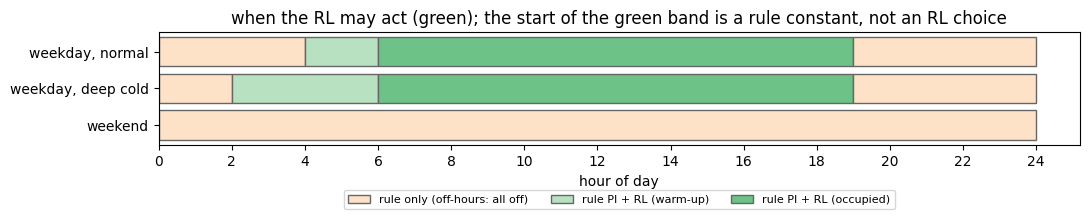

In [4]:
fig, ax = plt.subplots(figsize=(11, 2.6))
spans = {'weekday, normal': [(0, 4, 'rule only (off-hours: all off)'), (4, 6, 'rule PI + RL (warm-up)'), (6, 19, 'rule PI + RL (occupied)'), (19, 24, 'rule only (off-hours: all off)')],
         'weekday, deep cold': [(0, 2, 'rule only (off-hours: all off)'), (2, 6, 'rule PI + RL (warm-up)'), (6, 19, 'rule PI + RL (occupied)'), (19, 24, 'rule only (off-hours: all off)')],
         'weekend': [(0, 24, 'rule only (off-hours: all off)')]}
col = {'rule only (off-hours: all off)': '#fde2c8', 'rule PI + RL (warm-up)': '#b7e1c1', 'rule PI + RL (occupied)': '#6cc287'}
for i, (row, ss) in enumerate(spans.items()):
    for a, b, lab in ss:
        ax.barh(i, b - a, left=a, color=col[lab], edgecolor='0.4', label=lab)
ax.set_yticks(range(len(spans))); ax.set_yticklabels(list(spans)); ax.invert_yaxis(); ax.set_xticks(range(0, 25, 2)); ax.set_xlabel('hour of day')
h, l = ax.get_legend_handles_labels(); u = dict(zip(l, h)); ax.legend(u.values(), u.keys(), fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.35), ncol=3)
ax.set_title('when the RL may act (green); the start of the green band is a rule constant, not an RL choice'); plt.tight_layout(); plt.show()

**What.** Inside those hours, lever by lever:

| lever | who sets it | what the RL can do |
|---|---|---|
| when the warm-up starts and the day ends | **rule only** (fixed constants) | nothing |
| everything at night and at weekends | **rule only** (all off, recirculation on) | nothing |
| zone damper and reheat valve | rule (per-zone PI loop) **+ RL** correction | adds a correction every 5 minutes; the PI loop's integral pulls a lasting push back out |
| zone target temperature | **rule** (band centre, shifted by demand) | nothing in the shipped weights; a +-1 K target output is being trained (section 4c) |
| air handler supply temperature, static pressure, outside-air share | rule **+ RL** correction | adds a correction every 5 minutes |
| air handler on/off | **rule** (every air handler forced on in PI hours) | a switch vote through a dead zone, rarely cast; a learned on/off output is being trained (section 6) |
| hot-water temperature and pressure | rule (follows the zones' heat demand) **+ RL** correction | adds a correction every 5 minutes |
| boiler pump on/off | **rule** (on in PI hours) | the same vote; the same new on/off output |

So the RL fine-tunes continuous setpoints during working hours.
The decisions that set most of the heat, when the warm-up starts and which units run, are still the rule's.
Section 4c measures what that costs, and section 6 says how we are moving those decisions to the learner.

## 2. The network: one small net per entity type, shared across buildings

Buildings differ in size, so the policy has **one zone net applied to every zone, one AHU net to every AHU, one plant net**.
The same weights serve a 30-zone and an 85-zone building.
Each net reads only its own entity's features (its sensors, its comfort-band errors, the rule's proposal for it, its AHU's state,
time and weather), and outputs that entity's correction. The AHU features include pooled statistics of its zones.

Exploration is a Gaussian on each correction; on/off switches are votes that only flip a switch past +-0.5.
The critic (value function) mean-pools all entity embeddings.

In [5]:
import torch
from skynet.features import ZONE_FIELDS, AHU_FIELDS, PLANT_FIELDS, GLOBAL_FIELDS, N_ZONE, N_AHU, N_PLANT, ZONE_OUT, AHU_OUT, PLANT_OUT
from skynet.policy import load
NET, PARAMS, SCALE, LATCH = load(W / 'skynet.pt')
print(f'zone net: {N_ZONE} inputs -> {ZONE_OUT} corrections (damper, reheat)')
print(f'AHU net:  {N_AHU} inputs -> {AHU_OUT} (supply temperature, pressure, recirculation, run vote)')
print(f'plant net: {N_PLANT} inputs -> {PLANT_OUT} (water temperature, pressure, pump vote)')
print('zone sensor fields:', [f for f, _ in ZONE_FIELDS])
print('global fields:', GLOBAL_FIELDS, '+ occupancy, outside temperature, in-comfort-hours flag')
print(f'parameters: {sum(p.numel() for p in NET.parameters()):,}  | base {PARAMS} | correction scale {SCALE}')

zone net: 21 inputs -> 3 corrections (damper, reheat)
AHU net:  34 inputs -> 4 (supply temperature, pressure, recirculation, run vote)
plant net: 22 inputs -> 3 (water temperature, pressure, pump vote)
zone sensor fields: ['zone_air_temperature_sensor', 'zone_air_heating_temperature_setpoint_sensor', 'zone_air_cooling_temperature_setpoint_sensor', 'supply_air_damper_percentage_command', 'reheat_valve_percentage_command', 'supply_air_flowrate_setpoint']
global fields: ['hod_sin_000', 'hod_cos_000', 'dow_sin_000', 'dow_cos_000', 'comfort_mode_now', 'comfort_mode_soon'] + occupancy, outside temperature, in-comfort-hours flag
parameters: 48,211  | base {'controller': 'zt_off'} | correction scale 1.0


## 3. Training

PPO on 5 of the 6 training buildings x 5 climates = 25 scenarios, each a full 30-day episode, played back to back by 6 parallel workers.
Building 8 is **never trained on**; every checkpoint is scored on its 5 climates with the mean action (no exploration noise).
A second fold holds out building 7 instead.
This run was warm-started from an earlier 254k-step run of the same net on the plain zt base.

In [6]:
a = C['args']
print('PPO settings of the shipped run:')
for k in ('n_steps', 'workers', 'epochs', 'minibatch', 'lr', 'gamma', 'lam', 'clip', 'vf_coef', 'reward_scale', 'scale', 'd', 'depth'):
    print(f'  {k:13s} {a[k]}')
print(f"  rollout per update = n_steps x workers = {a['n_steps'] * a['workers']} steps; one 30-day episode = 8,640 steps")

PPO settings of the shipped run:
  n_steps       512
  workers       6
  epochs        4
  minibatch     256
  lr            0.0003
  gamma         0.995
  lam           0.95
  clip          0.2
  vf_coef       0.5
  reward_scale  10.0
  scale         1.0
  d             64
  depth         2
  rollout per update = n_steps x workers = 3072 steps; one 30-day episode = 8,640 steps


## 4. Results

The held-out curve is the honest one: building 8 is a building the policy has never seen.

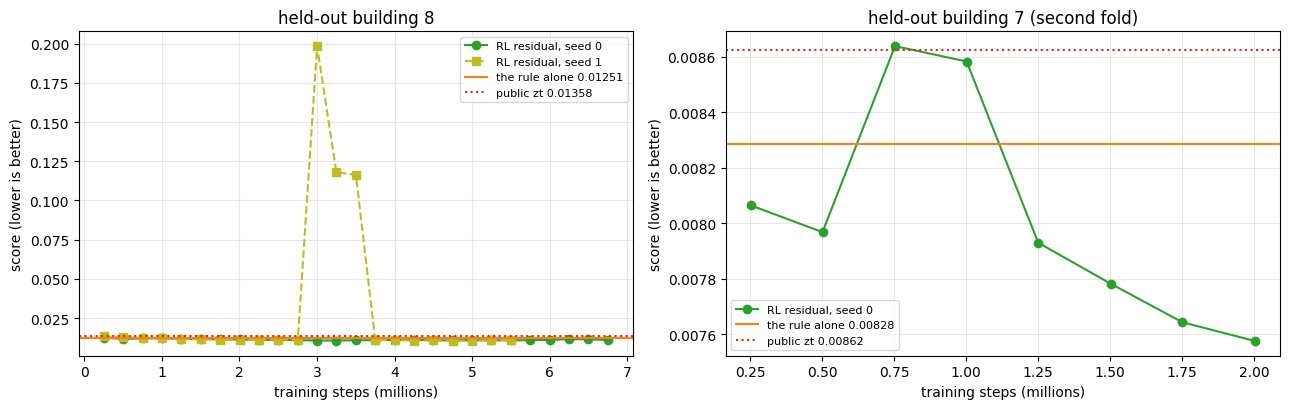

best building-8 checkpoint 5,001,216 steps: 0.01040 vs rule 0.01251 (-16.9%)  | shipped weights: m1c_ztoff_s10_seed1@5001216


In [7]:
mean = lambda s: float(np.mean(list(s.values())))
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, key, rule, zt, title in [(axs[0], 'rl_b8_seed0', 'rule_b8', 'zt_b8', 'held-out building 8'),
                                 (axs[1], 'rl_b7_seed0', 'rule_b7', 'zt_b7', 'held-out building 7 (second fold)')]:
    e = C[key]; ax.plot([r['steps'] / 1e6 for r in e], [mean(r['scores']) for r in e], 'o-', label='RL residual, seed 0', color='tab:green')
    if key == 'rl_b8_seed0':
        e1 = C['rl_b8_seed1']; ax.plot([r['steps'] / 1e6 for r in e1], [mean(r['scores']) for r in e1], 's--', label='RL residual, seed 1', color='tab:olive')
    ax.axhline(mean(C[rule]), color='tab:orange', label=f'the rule alone {mean(C[rule]):.5f}')
    ax.axhline(mean(C[zt]), color='tab:red', ls=':', label=f'public zt {mean(C[zt]):.5f}')
    ax.set_xlabel('training steps (millions)'); ax.set_ylabel('score (lower is better)'); ax.set_title(title); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
best = min(C['rl_b8_seed0'] + C['rl_b8_seed1'], key=lambda r: mean(r['scores']))
print(f"best building-8 checkpoint {best['steps']:,} steps: {mean(best['scores']):.5f} vs rule {mean(C['rule_b8']):.5f} "
      f"({100 * (mean(best['scores']) / mean(C['rule_b8']) - 1):+.1f}%)  | shipped weights: {C['tag']}")

Reading it:

- The RL beats its own rule on both held-out buildings. Seed 1 at 5.0M steps is the best checkpoint so far, 0.01040 (-16.9% vs the rule); these are its weights. Past 5.0M it got worse again (0.01111 at 5.5M).
- The curve is not monotone: it got **worse** between 500k and 1M steps before improving again. Stopping at the dip would have been wrong (we nearly did).
- Seed 0 peaked at 3.0M (0.01065) and has drifted to about 0.011 since, out to 6.75M; seed 1 overtook it after 4M. One seed is not the whole story, and neither is one checkpoint.
- Seed 1's mean hides a near-miss: at 3.0-3.5M its Fairbanks (coldest climate) score jumped from 0.027 to 0.96, 0.56 and 0.55, then came back to 0.027 at 3.75M. The 3.0M mean (0.198) only looks bad because of that one climate. Check the worst climate of a checkpoint, not just its mean.

Where the gain comes from, per climate:

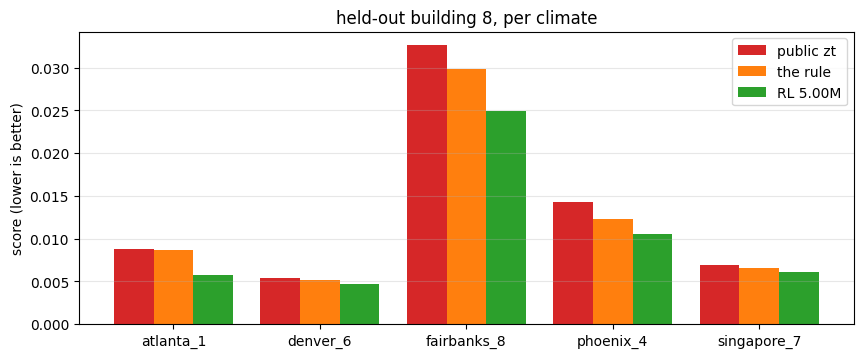

atlanta_1      rule 0.00864  RL 0.00579  (-33.0%)
denver_6       rule 0.00519  RL 0.00469  (-9.6%)
fairbanks_8    rule 0.02989  RL 0.02490  (-16.7%)
phoenix_4      rule 0.01233  RL 0.01050  (-14.8%)
singapore_7    rule 0.00651  RL 0.00610  (-6.3%)


In [8]:
cl = list(C['rule_b8']); x = np.arange(len(cl)); w = 0.27
fig, ax = plt.subplots(figsize=(10, 3.8))
for i, (lab, s, c) in enumerate([('public zt', C['zt_b8'], 'tab:red'), ('the rule', C['rule_b8'], 'tab:orange'), (f"RL {best['steps']/1e6:.2f}M", best['scores'], 'tab:green')]):
    ax.bar(x + (i - 1) * w, [s[k] for k in cl], w, label=lab, color=c)
ax.set_xticks(x); ax.set_xticklabels(cl); ax.set_ylabel('score (lower is better)'); ax.set_title('held-out building 8, per climate'); ax.legend(); ax.grid(axis='y', alpha=.3)
plt.show()
for k in cl:
    print(f"{k:14s} rule {C['rule_b8'][k]:.5f}  RL {best['scores'][k]:.5f}  ({100 * (best['scores'][k] / C['rule_b8'][k] - 1):+.1f}%)")

Does the held-out building predict the leaderboard? For every submission so far, the board was 5-15% above held-out building 8,
and the order was the same (the longer RL runs sit at the top of that range):

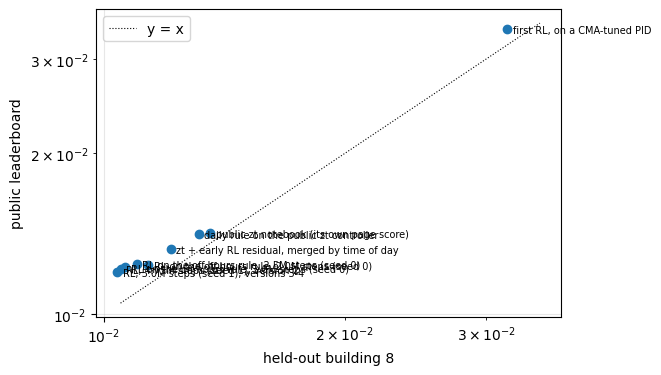

board / held-out: [1.153, 1.157, 1.149, 1.132, 1.089, 1.093, 1.077, 1.072, 1.046]


In [9]:
b = C['board']
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter([r['held_out'] for r in b], [r['board'] for r in b])
for r in b: ax.annotate(r['what'], (r['held_out'], r['board']), fontsize=7, xytext=(4, -3), textcoords='offset points')
lo, hi = 0.0105, 0.035; ax.plot([lo, hi], [lo, hi], 'k:', lw=.8, label='y = x'); ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('held-out building 8'); ax.set_ylabel('public leaderboard'); ax.legend(); ax.grid(alpha=.3); plt.show()
print('board / held-out:', [round(r['board'] / r['held_out'], 3) for r in b])

## 4b. Is part of the gain a billing bug? Yes, about 39%. The rest is real.

The simulator bills the boiler for hot water at its **setpoint**, but the coils draw water at the tank's **actual** temperature (forum discussion 752142; the organisers' fix is PR #2).
When the setpoint sits below the tank temperature, heat leaves the tank without being billed.
We never told the RL about this, and we never use it on purpose. It found it anyway: over 30 days in Fairbanks the 5.0M weights drew 914 kWh more heat from the tank than they were billed for.

To measure what is left without the bug we re-billed every run honestly: the flow is billed at the tank's actual temperature, the dynamics are unchanged
(the observations are byte-identical for 1,500 steps). We also ran the organisers' PR #2 simulator, which changes the tank itself.

| held-out building 8, 30 days | rule | RL 5.0M | RL gain |
|---|---:|---:|---:|
| simulator as shipped (the board today) | 0.01251 | 0.01040 | -16.9% |
| honest bill (flow billed at the tank temperature) | 0.01207 | 0.01079 | **-10.6%** |
| organisers' fix, PR #2 (energy-balanced tank) | 0.01178 | 0.01072 | -9.0% |

- **Negative:** 0.00211 of gain on the shipped bill, 0.00128 on the honest bill, so about 39% of the shipped gain depends on the bug.
- **Positive:** the rest survives both checks. Delivered heat in Fairbanks falls 7.2%; that is physics, not accounting.
- From here on every run we train and every number we compare is on the honest bill. A board score would still be on the shipped simulator.

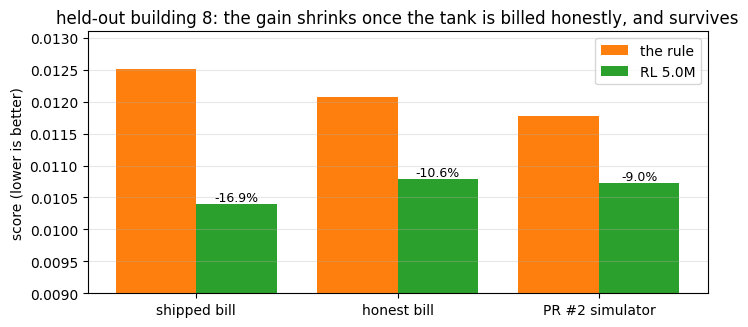

In [10]:
H = C['honest']; cl = list(H['rule'])
fig, ax = plt.subplots(figsize=(8, 3.4))
rows = [('shipped bill', 0.01251, 0.01040), ('honest bill', mean(H['rule']), mean(H['rl5m'])), ('PR #2 simulator', 0.01178, 0.01072)]
x = np.arange(len(rows))
ax.bar(x - 0.2, [r[1] for r in rows], 0.4, label='the rule', color='tab:orange'); ax.bar(x + 0.2, [r[2] for r in rows], 0.4, label='RL 5.0M', color='tab:green')
for i, (_, a, b) in enumerate(rows): ax.text(i + 0.2, b, f"{100 * (b / a - 1):+.1f}%", ha='center', va='bottom', fontsize=9)
ax.set_xticks(x); ax.set_xticklabels([r[0] for r in rows]); ax.set_ylim(0.009, 0.0131); ax.set_ylabel('score (lower is better)')
ax.set_title('held-out building 8: the gain shrinks once the tank is billed honestly, and survives'); ax.legend(); ax.grid(axis='y', alpha=.3); plt.show()

## 4c. What the RL cannot reach, and the first fix

Fairbanks is about half of the score. Where does its gas go? By hour of day (30 days, rule vs RL 5.0M):

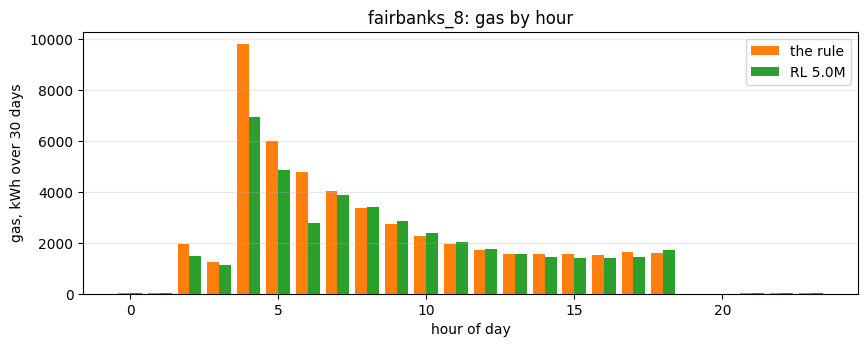

rule: 42% of the gas burns at 04:00-06:59, the morning warm-up


In [11]:
g = C['gas_hours']
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar([r['hour'] - 0.2 for r in g], [r['rule'] for r in g], 0.4, label='the rule', color='tab:orange')
ax.bar([r['hour'] + 0.2 for r in g], [r['rl'] for r in g], 0.4, label='RL 5.0M', color='tab:green')
ax.set_xlabel('hour of day'); ax.set_ylabel('gas, kWh over 30 days'); ax.set_title('fairbanks_8: gas by hour'); ax.legend(); ax.grid(axis='y', alpha=.3); plt.show()
tot = sum(r['rule'] for r in g); early = sum(r['rule'] for r in g if 4 <= r['hour'] <= 6)
print(f"rule: {100 * early / tot:.0f}% of the gas burns at 04:00-06:59, the morning warm-up")

Reading it:

- Almost all of the gas (99.8%) burns in the hours the residual may act, and the largest share is the morning warm-up.
- Yet the RL saves almost nothing in daytime, and its Fairbanks score (0.02633) equals the tuned rule's. Why? Most heat is set by levers the residual cannot move:
  - the residual acts only inside the rule's PI hours, so **when** the warm-up starts is the rule's choice, not the RL's;
  - every air handler is forced on in those hours, so it always heats 30% outside air;
  - each zone's PI loop pulls the temperature back to its target, so a residual push on a damper is cancelled by the loop's integral;
  - the net sees neither the PI's target nor its integral.
- **The first fix: give the RL the target.** A third output per zone shifts the PI's own target by up to +-1 K (inside the comfort band), so the loop helps instead of fighting.
  Started from the 5.0M weights, on the CMA-tuned rule, honest bill:

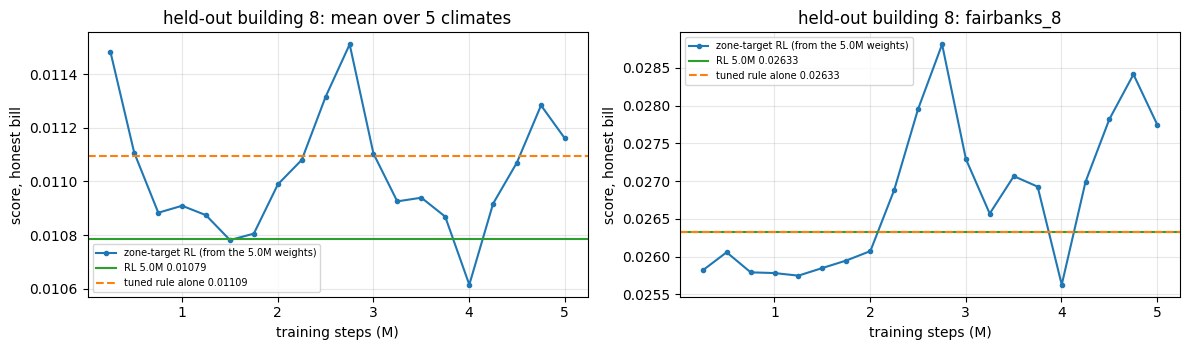

  251,904 steps  mean 0.01148  atlanta 0.00686  denver 0.00561  fairbanks 0.02582  phoenix 0.01253  singapore 0.00660
  500,736 steps  mean 0.01111  atlanta 0.00662  denver 0.00508  fairbanks 0.02606  phoenix 0.01163  singapore 0.00615
  752,640 steps  mean 0.01088  atlanta 0.00677  denver 0.00519  fairbanks 0.02579  phoenix 0.01057  singapore 0.00609
1,001,472 steps  mean 0.01091  atlanta 0.00683  denver 0.00528  fairbanks 0.02578  phoenix 0.01045  singapore 0.00621
1,250,304 steps  mean 0.01087  atlanta 0.00683  denver 0.00539  fairbanks 0.02575  phoenix 0.01025  singapore 0.00616
1,502,208 steps  mean 0.01078  atlanta 0.00654  denver 0.00500  fairbanks 0.02585  phoenix 0.01036  singapore 0.00616
1,751,040 steps  mean 0.01081  atlanta 0.00654  denver 0.00511  fairbanks 0.02595  phoenix 0.01029  singapore 0.00615
2,002,944 steps  mean 0.01099  atlanta 0.00656  denver 0.00552  fairbanks 0.02607  phoenix 0.01040  singapore 0.00639
2,251,776 steps  mean 0.01108  atlanta 0.00662  denver 0

In [12]:
zt_ = C['honest']['zone_target']; ref = C['honest']
x = [r['steps'] / 1e6 for r in zt_]
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, key, title in [(axs[0], None, 'mean over 5 climates'), (axs[1], 'fairbanks_8', 'fairbanks_8')]:
    get = (lambda s: mean(s)) if key is None else (lambda s: s[key])
    ax.plot(x, [get(r['scores']) for r in zt_], 'o-', ms=3, color='tab:blue', label='zone-target RL (from the 5.0M weights)')
    ax.axhline(get(ref['rl5m']), color='tab:green', label=f"RL 5.0M {get(ref['rl5m']):.5f}")
    ax.axhline(get(ref['cma_rule']), color='tab:orange', ls='--', label=f"tuned rule alone {get(ref['cma_rule']):.5f}")
    ax.set_xlabel('training steps (M)'); ax.set_ylabel('score, honest bill'); ax.set_title(f'held-out building 8: {title}'); ax.legend(fontsize=7); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()
for r in zt_:
    print(f"{r['steps']:>9,} steps  mean {mean(r['scores']):.5f}  " + '  '.join(f"{k.split('_')[0]} {v:.5f}" for k, v in r['scores'].items()))
print(f"RL 5.0M        mean {mean(ref['rl5m']):.5f}  |  tuned rule alone {mean(ref['cma_rule']):.5f}")

The run went to 5M steps. Reading it:

- **Positive:** Fairbanks moves below the rule for the first time: 0.02563 at its best checkpoint (4.0M) against 0.02633 for both the tuned rule and the 5.0M weights. Phoenix improves steadily, to about 0.0101 against 0.01050.
  At 250k it gained in Fairbanks and lost in Phoenix; by 750k it held both. It does learn to act differently per climate, given time.
- **Negative:** the mean only ties the 5.0M weights. The best single checkpoint is 0.01062 (4.0M), but checkpoints bounce by about 0.00025 (one standard deviation), and the best 3-checkpoint average is 0.01080 against 0.01079.
  Between 1.5M and 2.75M it drifted to 0.01151, mostly in Fairbanks (0.02881), then recovered: the same overtraining swing as every earlier run.
- **Check on a second building** (building 7, which these runs train on, honest bill): 5.0M 0.00749, the zone-target run at 4.0M 0.00755. Fairbanks is better there too (0.00949 vs 0.01015), Denver worse (0.00745 vs 0.00581).
- So the shipped weights stay 5.0M. The zone-target run's 4.0M checkpoint is the starting point for the next experiment (section 6).

## 5. What failed (measured, held-out building 8 unless stated)

| attempt | result | why, as far as we know |
|---|---|---|
| RL on a CMA-tuned PID (organisers' pid_water) | 0.03184 held-out, board 0.03414 | the base was far worse than per-zone PI; a residual cannot move far from a bad base |
| RL on a CMA-tuned version of the zt rule | 0.01196 at 500k, then worse every checkpoint to 0.01275 at 1.25M | stopped; the tuned base starts better (0.01187) but the RL on top never beat it |
| hold each correction for an hour (decide once per hour) | 0.01265-0.01345, worse than every-step | the gain is in reacting fast, not in fewer decisions |
| paired reward (minus a zt shadow run) + low noise + 1 h switch latch, on plain zt (no off-hours rule) | 0.01298-0.01307 from 750k to 1.5M, flat | a small gain over zt (0.01358) at 2x simulation cost; the off-hours rule as base does far better |
| cut exploration noise to a quarter without lowering the learning rate | clip fraction 0.19-0.34 after 5 updates; stopped | the same mean shift is a 4x bigger probability ratio; lr must fall with the noise |
| stopping at the 1M dip | would have kept 0.01203 instead of 0.01065 | the held-out curve bounces by about +-0.0005 between checkpoints |
| training seed 0 on past its best (3.0M -> 6.75M) | 0.01065 -> 0.0110-0.0115 | **HYPOTHESIS:** overfitting the 25 training scenarios; exploration noise keeps falling (entropy 15.6 -> 8.4) |
| trusting the mean score | seed 1 at 3.0M: 0.198 mean, 0.96 in Fairbanks alone | a cold-climate failure for three checkpoints, then recovered; screen every checkpoint's worst climate |
| a single 5-minute switch vote | about 1/100 of the reward noise | on/off switches are barely learnable with per-step Gaussian votes |
| training seed 1 on past 5.0M | 0.01040 at 5.0M, 0.01090 at 5.25M, 0.01111 at 5.5M | the same overtraining pattern as seed 0, one seed later; keep the best checkpoint, not the last |
| averaging seed 1's weights over 4.0M-5.0M | 0.01054 vs 0.01040 for the 5.0M checkpoint alone | no gain; the snapshots are not in one flat basin |
| residual active in every hour, not only zt's PI hours | 0.01079, 0.01073, 0.01078 at 250k / 500k / 750k from the 5.0M weights | flat and worse; outside the PI hours the off-hours rule is already near its floor |
| residual on the CMA-tuned rule, from the 5.0M weights | 0.01126 at 250k | worse so far; the weights learned corrections for the untuned rule |
| bigger nets on Kaggle CPU (d128x3, d256x3, d512x3; this net is d64x2) | best 0.01229, 0.01237, 0.01340 by 0.75-1.25M; d256x3 then rose to 0.01426 | all worse than d64x2 at the same steps; stopped |
| a 30-point grid over the rule's own constants (pre-start hours, heat damper, water max) | best point +0.00007 vs the shipped constants on building 8 | null; the shipped rule constants stay |
| lower exploration noise with a matching learning rate, from the 5.0M weights | 0.01038, 0.01042, 0.01044 at 250k / 500k / 1M vs 0.01040 | null; closed |
| adding 1,000 generated buildings to the training pool, from the 5.0M weights (honest bill) | 0.01079 at 250k, the same as the start | null at the first check; stopped to free the cores for the zone-target run |
| zone-target head on the untuned rule, from the 5.0M weights (honest bill) | 0.01090, 0.01094 at 250k / 500k vs 0.01079 | flat; its Fairbanks gain at 250k (0.02613) was gone by 500k (0.02642). The same head on the tuned rule works better (section 4c) |
| the RL's gain taken at face value | 39% of it was the tank-billing bug | section 4b; we now train and compare on the honest bill |
| zone-target head trained to 5M (honest bill) | best 3-checkpoint average 0.01080 vs 0.01079 for 5.0M; 0.01151 at 2.75M | a Fairbanks gain, no gain on the mean; section 4c |
| cold-weighted generated buildings (20 cold to 2 others), from 5.0M, shipped bill | 0.01057, 0.01094 at 250k / 500k vs 0.01040 | worse even on the bill it trained on; stopped |
| the rule's warm-up start as tuned constants (CMA-ES, 4 of 12 generations so far) | best 0.011729 vs 0.011715 at the start, on 17 training scenarios | no gain yet; the run continues |

Not a failure, a check: is the RL overfitting the training buildings? On building 7, **which these weights trained on**, they score 0.00726 (-12.4% vs the rule); on building 8, which they never saw, -16.9%. The unseen building gains at least as much as a training building, so we see no overfitting to the training set.
The true second fold is a separate run with building 7 held out (seed 0, stopped at 2.0M steps): 0.00758 vs the rule's 0.00828, **-8.6%** (section 4, right plot). (Versions 3 and 4 of this notebook called the 0.00726 a held-out result; it is not.)
On training building 1 (Fairbanks, Atlanta, Denver, Phoenix, Singapore; 7 days) the 5.0M weights score 0.01411 vs 0.01609 for the rule.

We do **not** use the simulator bugs reported on the forum on purpose (the hot-water tank billed at its setpoint, PR #2; the area-weighted return-air temperature, discussion 753804).
The RL found part of the first one by itself (section 4b); every run since is trained and compared on an honest bill. Whether it picks up part of the second one through the dampers is not measured.

## 6. Where next (runs in progress, all on the honest bill)

- **Give the RL the on/off switches.** Until now every switch (each air handler's run command, the boiler pump) was a Gaussian output through a dead zone, so a learned switch decision was almost impossible.
  The switches are now Bernoulli outputs: the probability of doing the opposite of the rule, starting at about 5% while exploring and at "follow the rule" in the deterministic policy.
  Trained from the zone-target run's 4.0M checkpoint; the question is whether it learns to switch an air handler off when its zones do not need it, and whether that beats 0.01079 by 0.0005.
  If it learns nothing in 1M steps, the next step is a prior, not a rule: start the switch output from "off while every zone is in band" and let PPO keep it or drop it.
- **Let the warm-up start move.** CMA-ES on the rule's warm-up constants (pre-start hours, deep-cold pre-start and threshold, a start that opens early while zones are cold, damper floor), on the shipped plus generated buildings. If tuning those cannot cut Fairbanks gas, a learned start will not either.
- **Show the net the PI's target and integral** (proposed): the zone-target head can move the target, but it cannot see where it is or how far the loop has wound up.
- **Graph attention** across the zones of one air handler: running on Kaggle CPU.
- **Faster training.** One thread per simulator process took a 6-worker run from about 45 to 110-135 steps per second on a laptop.
  Letting each worker sample with its own copy of the network and step until a shared step counter is reached (no waiting for the slowest building at every step) took it to about 208 steps per second.
- **Memory** (from v1): the net sees one 5-minute observation with no trend.

## 7. Credits

- **malyshevdanil**: the per-zone PI controller (zt) that is the base rule ([notebook](https://www.kaggle.com/code/malyshevdanil/smart-buildings-probe-zt-best), Apache-2.0).
- The organisers: the simulator, the `PIDWaterResetPolicy` baseline (Apache-2.0) and the evaluation gateway.

## The submission

The cell below serves the policy to the competition's gateway. With the dataset's weights it reproduces the training environment's
scores to within 1e-8 (checked offline on 1,500 steps of each held-out climate).

In [13]:
torch.set_num_threads(1)
from smart_buildings.baselines.pid_plus import PIDWaterResetPolicy
from smart_buildings.evaluate import validate_action
from kaggle_evaluation import smart_buildings_inference_server as sbis
from skynet.policy import SkynetPolicy


class SubmissionPolicy(sbis.Policy):
    def __init__(self, building_meta_data, action_spec):
        super().__init__(building_meta_data, action_spec)
        self.p = SkynetPolicy(building_meta_data, action_spec, NET, PARAMS, SCALE, PIDWaterResetPolicy, validate_action, LATCH)

    def get_action(self, obs):
        return self.p.get_action(obs)


sbis.SmartBuildingsInferenceServer(SubmissionPolicy).run(competition_data_folder=str(DATA_ROOT))

Episode finished! Total reward: {'agent_0': -37.18995660186738}
[gateway] building_train_1/atlanta_2: mean reward=-0.0043 over 8641 steps in 751s
[gateway] mean scenario reward total, for logs only: -0.0043
